# **MACE Hands-on: Si–Li Interatomic Potentials**
Training from scratch → Pretrained zero-shot → Fine-tuning 

**Learning goals | Workflow :** Understand the DFT reference dataset, train an MLIP, test a pretrained foundation model, fine-tune it, and compare predictions on identical held-out configurations.

**Dataset :** 192 train / 96 validation / 96 test configurations. Models trained on these tiny subsets are demonstrations, **not validated potentials**. 


This notebook is a python interactive tutorial

I recommend using a GPU. when using Colab, go to:\
[`Runtime`] → [`Change runtime type`] → [`T4 GPU`] → [`Save`]\
You can use CPU, but it is very slow and you should change the code.
[`'device': 'cuda'`] → [`'device': 'cpu'`]

If you're using Colab, it may crash occasionally. If it does, try starting from the beginning or from the cell where it crashed. If that doesn’t work, go to: \
[`Runtime`] → [`Disconnect and delete runtime`] → restart the tutorial

Note : I checked with collab CPU and the max time took for a cell is 8 min only


## **SECTION 1 : Preparation**

### **0. Installation| Environments | GPU** 
Colab supplies python and usually Pytorch. We need to install **MACE 0.3.16**. If installing changes dependencies, restart the runtime before continuing. GPU access depends on colab availability

In [1]:
import sys, subprocess
print('Python:',sys.version.split()[0])

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'mace-torch==0.3.16', 'ase', 'numpy', 'pandas', 'matplotlib'], check=True)
print('Installation done. Restart runtime only if Colab requests it.')

Python: 3.11.15
Installation done. Restart runtime only if Colab requests it.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import torch, ase, mace
from pathlib import Path

print('PyTorch:', torch.__version__)
print('ASE:', ase.__version__)
print('MACE installed:', mace.__file__)
print('CUDA available:',torch.cuda.is_available())

if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))
assert torch.cuda.is_available(), 'Select a GPU runtime before hands-on training.' 

PyTorch: 2.13.0+cu130
ASE: 3.29.0
MACE installed: /home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/mace/__init__.py
CUDA available: True
GPU: NVIDIA GeForce RTX 4070 Ti SUPER


### **1. Get the dataset from github** 
The public repository contains the three **small** XYZ files in `data/`,named: 

`SiLi_train.xyz`,  

`SiLi_valid.xyz`, and  

`SiLi_test.xyz`.  

Training/validation/test originate from different source starting-structure trajectories (Str1/Str2/Str3). Files use custom label keys `DFT_energy` and `DFT_forces`.

#### **Downloading the Tutorial Dataset**

The Si–Li AIMD dataset is hosted in the [GitHub repository](https://github.com/Bincy97/MACE_SiLi_Practice_Tutorial).

The following code automatically detects whether the notebook is running in **Google Colab or on a local PC** and downloads the repository to the appropriate location.

- **Google Colab:** The repository is downloaded into Colab's `/content/` directory.
- **Local PC:** The repository is downloaded into a folder on your computer.

Once downloaded, the notebook reads the three XYZ files (`SiLi_train.xyz`, `SiLi_valid.xyz`, and `SiLi_test.xyz`) from the local copy. 

If the repository folder already exists, the download is skipped.

**Note:** An internet connection is required for the initial download. Subsequent calculations use the downloaded files.

In [3]:

import subprocess
from pathlib import Path

REPO_URL = "https://github.com/Bincy97/MACE_SiLi_Practice_Tutorial.git"

# Detect Google Colab or local Linux
try:
    import google.colab
    ROOT = Path("/content/MACE_SiLi_Practice_Tutorial")
except ImportError:
    ROOT = Path.home() / "Desktop/MLIP_tutorial/github_tutorial"

# Download repository if not already present
if not ROOT.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(ROOT)],
        check=True
    )

DATA = ROOT / "data"

TRAIN = DATA / "SiLi_train.xyz"
VALID = DATA / "SiLi_valid.xyz"
TEST = DATA / "SiLi_test.xyz"

for path in [TRAIN, VALID, TEST]:
    assert path.is_file(), f"Missing dataset: {path}"
    print(f"{path.name}: {path.stat().st_size / 1024:.1f} KiB")

print("\nDataset loading successful!")
print("Working directory:", ROOT)


SiLi_train.xyz: 1407.8 KiB
SiLi_valid.xyz: 703.9 KiB
SiLi_test.xyz: 703.9 KiB

Dataset loading successful!
Working directory: /home/bincy/Desktop/MLIP_tutorial/github_tutorial


### **2. Inspect the DFT data** 
An extended XYZ frame stores elements, positions, periodic cell and DFT labels. Energy is one scalar per configuration (eV); forces are one 3D vector per atom (eV/Å). We access our **custom keys** directly; `atoms.get_potential_energy()` is not appropriate unless a calculator is attached.

In [4]:
from ase.io import read
import numpy as np

first = read(str(TRAIN), index=0, format='extxyz')

print('Composition:', first.get_chemical_formula(), 'Atoms:',len(first))
print('PBC:', first.pbc, 'Cell (Å):', first.cell.lengths())
print('Energy (eV):',first.info['DFT_energy'])
print('Force shape:',first.arrays['DFT_forces'].shape)
print('Metadata:',sorted(first.info.keys()))

Composition: LiSi64 Atoms: 65
PBC: [ True  True  True] Cell (Å): [ 8.64453859 11.24227039 11.27178381]
Energy (eV): -338.14218129
Force shape: (65, 3)
Metadata: ['DFT_energy', 'Li_count', 'config_type', 'frame_index_0based', 'source_id', 'structure_id', 'temperature_K']


In [5]:
# load all frames for exploration.

sets = {label:read(str(path),index=':',format='extxyz') for label,path in
        [('train',TRAIN),('valid',VALID),('test',TEST)]}

for label,frames in sets.items():
    counts = {(int(a.info['Li_count']), int(a.info['temperature_K'])) for a in frames}
    assert len(counts)==24, (label,len(counts))
    assert all('DFT_energy' in a.info and 'DFT_forces' in a.arrays for a in frames)
    print(label, len(frames), 'frames; concentration-temperature groups:',len(counts))

train 192 frames; concentration-temperature groups: 24
valid 96 frames; concentration-temperature groups: 24
test 96 frames; concentration-temperature groups: 24


#### **a. DFT Energy Distribution** 
Plot DFT energy **per atom** by Li count. Differences across compositions include changes in chemistry and reference offsets; do **not** interpret this plot as a Li insertion phase-stability diagram.

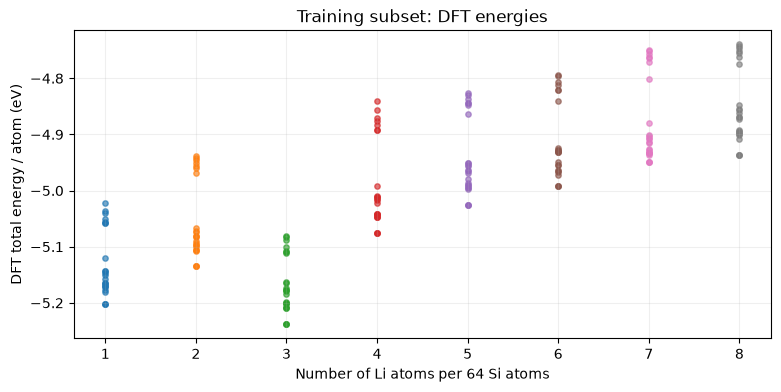

In [6]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,4))

for li in range(1,9):
    vals=[float(a.info['DFT_energy'])/len(a) for a in sets['train'] if int(a.info['Li_count'])==li]
    ax.scatter([li]*len(vals), vals, s=15, alpha=.65)
    
ax.set(xlabel='Number of Li atoms per 64 Si atoms',ylabel='DFT total energy / atom (eV)',title='Training subset: DFT energies')
ax.grid(alpha=.2); plt.show()

#### **b. DFT Force Distribution** 
Compare magnitudes $|\mathbf F|$ for Li and Si. MACE learns force *components*, and the force is the negative gradient of predicted energy: $\mathbf F_i=-\nabla_i E$.

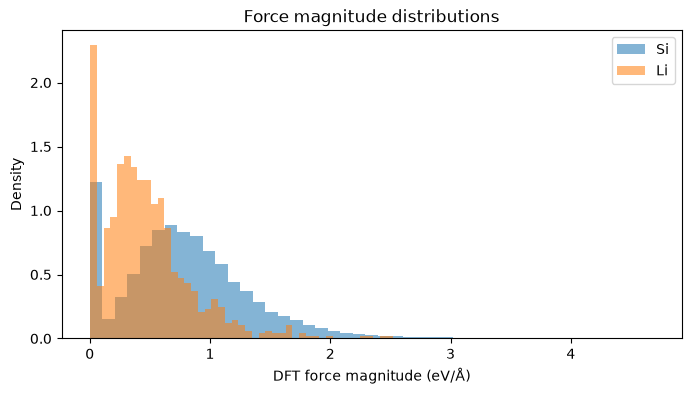

In [7]:
F_li, F_si=[],[]

for a in sets['train']:
    norms=np.linalg.norm(a.arrays['DFT_forces'],axis=1)
    F_li.extend(norms[a.numbers==3]); F_si.extend(norms[a.numbers==14])

plt.figure(figsize=(8,4))
plt.hist(F_si,bins=45,alpha=.55,density=True,label='Si')
plt.hist(F_li,bins=45,alpha=.55,density=True,label='Li')
plt.xlabel('DFT force magnitude (eV/Å)'); plt.ylabel('Density');plt.legend();plt.title('Force magnitude distributions');plt.show()

## **SECTION 2 : MLIP Training**


## **1. Model A: Train MACE from SCRATCH** 

Training from scratch means how we initialize the MACE Model. We will use MACE architecture with newly initialized parameters rather than loading parameters from a pre-trained model. 

##### **Main Parameters Used in MACE Training**

The following parameters define the model architecture, DFT reference data, and training procedure.

| Parameter | Definition |
|---|---|
| `--name` | Name assigned to the training experiment and its output files. |
| `--model` | Neural-network architecture used for training (e.g., `MACE`). |
| `--train_file` | Path to the training dataset containing DFT reference configurations. |
| `--valid_file` | Path to the validation dataset used to monitor model performance. |
| `--energy_key` | Property name containing DFT reference energies. |
| `--forces_key` | Property name containing DFT reference atomic forces. |
| `--r_max` | Cutoff radius (Å) defining which neighboring atoms interact directly. |
| `--num_interactions` | Number of message-passing layers in the MACE model. |
| `--num_channels` | Number of learned features used to represent atomic environments. |
| `--max_L` | Maximum angular degree used for the hidden feature representations. |
| `--batch_size` | Number of atomic configurations processed per training batch. |
| `--max_num_epochs` | Maximum number of complete passes through the training dataset. |
| `--lr` | Learning rate controlling the size of optimizer parameter updates. |
| `--energy_weight` | Relative weight assigned to energy errors in the loss function. |
| `--forces_weight` | Relative weight assigned to force errors in the loss function. |
| `--E0s` | Element-specific reference-energy offsets used in the energy model. |
| `--default_dtype` | Numerical precision used for calculations, such as `float32` or `float64`. |
| `--device` | Computing device used for training, such as `cuda` (GPU) or `cpu`. |
| `--seed` | Random seed used to improve reproducibility of model initialization and training. |
| `--foundation_model` | Loads a pretrained MACE model; omitted when training from scratch. |

**Note:** For training from scratch, we use `--model="MACE"` without specifying `--foundation_model`. This creates a new model whose trainable parameters are initialized rather than loaded from a pretrained checkpoint.

Initialize **random weights** and fit the DFT labels. `--E0s=average` obtains composition-dependent baseline atomic energies by least squares on *training only*. Small model = 32 channels, two interactions, 5 Å cutoff. `batch_size=2` means 96 gradient updates per epoch for 192 frames.


### **0. Definie the model parameters and other settings necessary for training**

In [8]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import time
import subprocess
import shlex
import torch
from pathlib import Path


# ============================================================
# 2. DEFINE OUTPUT DIRECTORY (PC + GOOGLE COLAB)
# ============================================================

# ROOT, TRAIN and VALID come from the dataset-loading cell
OUT = ROOT / "mace_runs"
OUT.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Training output directory:", OUT)
print("Computing device:", DEVICE)


# ============================================================
# 3. FUNCTION TO RUN MACE AND SAVE LOGS
# ============================================================

def run_mace(args, log_file):

    print("Command:", " ".join(shlex.quote(str(x)) for x in args))

    started = time.perf_counter()

    with open(log_file, "w") as log:

        process = subprocess.Popen(
            args,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1
        )

        for line in process.stdout:
            print(line, end="")
            log.write(line)

        rc = process.wait()

    if rc:
        raise RuntimeError(
            f"MACE exited with code {rc}; see {log_file}"
        )

    elapsed = (time.perf_counter() - started) / 60
    print(f"\nTraining completed in {elapsed:.1f} minutes")


# ============================================================
# 4. REUSABLE FUNCTION FOR SCRATCH TRAINING
# ============================================================

def train_scratch(model_name, learning_rate, epochs):

    # Create a separate output directory for each model
    prefix = OUT / model_name

    for part in ["models", "checkpoints", "results", "logs"]:
        (prefix / part).mkdir(parents=True, exist_ok=True)

    # Define training arguments
    args = [
        "mace_run_train",

        f"--name={model_name}",

        f"--train_file={TRAIN}",
        f"--valid_file={VALID}",

        "--energy_key=DFT_energy",
        "--forces_key=DFT_forces",

        "--model=MACE",
        "--r_max=5.0",
        "--num_interactions=2",
        "--num_channels=32",
        "--max_L=1",
        "--correlation=2",

        "--batch_size=2",
        "--valid_batch_size=2",

        f"--max_num_epochs={epochs}",
        f"--lr={learning_rate}",

        "--E0s=average",
        "--default_dtype=float32",
        f"--device={DEVICE}",
        "--num_workers=0",
        "--seed=42",

        f"--model_dir={prefix / 'models'}",
        f"--checkpoints_dir={prefix / 'checkpoints'}",
        f"--results_dir={prefix / 'results'}",
        f"--log_dir={prefix / 'logs'}",
    ]

    # Execute training
    print("\n" + "=" * 55)
    print(f"Model: {model_name}")
    print(f"Learning rate: {learning_rate}")
    print(f"Epochs: {epochs}")
    print("=" * 55)

    run_mace(args, prefix / "logs" / "terminal.log")

Training output directory: /home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs
Computing device: cuda


### **1. Model Training**

### **```1.1 [Model : MACE_Scratch_1]```**

In [9]:
# ============================================================
# MACE_Scratch_1: INITIAL TRAINING
# ============================================================

RUN_SCRATCH_1 = True

if RUN_SCRATCH_1:
    train_scratch(
        model_name="MACE_Scratch_1",
        learning_rate=0.01,
        epochs=3
    )


Model: MACE_Scratch_1
Learning rate: 0.01
Epochs: 3
Command: mace_run_train --name=MACE_Scratch_1 --train_file=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/data/SiLi_train.xyz --valid_file=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/data/SiLi_valid.xyz --energy_key=DFT_energy --forces_key=DFT_forces --model=MACE --r_max=5.0 --num_interactions=2 --num_channels=32 --max_L=1 --correlation=2 --batch_size=2 --valid_batch_size=2 --max_num_epochs=3 --lr=0.01 --E0s=average --default_dtype=float32 --device=cuda --num_workers=0 --seed=42 --model_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_1/models --checkpoints_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_1/checkpoints --results_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_1/results --log_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_1/logs
/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/e3

### **```1.2 [Model : MACE_Scratch_2]```**

In [10]:
# ============================================================
# MACE_Scratch_2: LOWER LEARNING RATE + MORE EPOCHS
# ============================================================

RUN_SCRATCH_2 = True

if RUN_SCRATCH_2:
    train_scratch(
        model_name="MACE_Scratch_2",
        learning_rate=0.001,
        epochs=10
    )


Model: MACE_Scratch_2
Learning rate: 0.001
Epochs: 10
Command: mace_run_train --name=MACE_Scratch_2 --train_file=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/data/SiLi_train.xyz --valid_file=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/data/SiLi_valid.xyz --energy_key=DFT_energy --forces_key=DFT_forces --model=MACE --r_max=5.0 --num_interactions=2 --num_channels=32 --max_L=1 --correlation=2 --batch_size=2 --valid_batch_size=2 --max_num_epochs=10 --lr=0.001 --E0s=average --default_dtype=float32 --device=cuda --num_workers=0 --seed=42 --model_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_2/models --checkpoints_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_2/checkpoints --results_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_2/results --log_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_2/logs
/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-package

### **```1.3 [Model : MACE_Scratch_3]```**

In [11]:
# ============================================================
# MACE_Scratch_3: FURTHER TRAINING EXPERIMENT
# ============================================================

RUN_SCRATCH_3 = True

if RUN_SCRATCH_3:
    train_scratch(
        model_name="MACE_Scratch_3",
        learning_rate=0.0005,
        epochs=20
    )


Model: MACE_Scratch_3
Learning rate: 0.0005
Epochs: 20
Command: mace_run_train --name=MACE_Scratch_3 --train_file=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/data/SiLi_train.xyz --valid_file=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/data/SiLi_valid.xyz --energy_key=DFT_energy --forces_key=DFT_forces --model=MACE --r_max=5.0 --num_interactions=2 --num_channels=32 --max_L=1 --correlation=2 --batch_size=2 --valid_batch_size=2 --max_num_epochs=20 --lr=0.0005 --E0s=average --default_dtype=float32 --device=cuda --num_workers=0 --seed=42 --model_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_3/models --checkpoints_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_3/checkpoints --results_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_3/results --log_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Scratch_3/logs
/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packa

### **1.4 Comparison of MACE Models** 

We trained three MACE models using the same DFT training dataset and model architecture but different learning rates and numbers of epochs.

We will now evaluate all three models using the same independent DFT test dataset.

The comparison includes:

**Energy RMSE (meV/atom)**: Measures the deviation between MACE-predicted and DFT energies per atom.

**Force RMSE (meV/Å)**: Measures the deviation between MACE-predicted and DFT atomic-force components.

Parity plots: Compare DFT reference values (x-axis) with MACE predictions (y-axis). The dashed line represents perfect agreement.

The objective is to examine how different training settings influence the model's prediction accuracy.

/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Test configurations: 96
Computing device: cuda
Evaluating MACE_Scratch_1 ...


/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/mace/calculators/mace.py:226: UserWarning: 'torch.load' received a zip file that looks like a TorchScript archive dispatching to 'torch.jit.load' (call 'torch.jit.load' directly to silence this warning)
  torch.load(f=model_path, map_location=device)


Evaluating MACE_Scratch_2 ...


/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/mace/calculators/mace.py:226: UserWarning: 'torch.load' received a zip file that looks like a TorchScript archive dispatching to 'torch.jit.load' (call 'torch.jit.load' directly to silence this warning)
  torch.load(f=model_path, map_location=device)


Evaluating MACE_Scratch_3 ...


,Model,Learning rate,Epochs,Energy RMSE (meV/atom),Force RMSE (meV/Å)
0,MACE_Scratch_1,0.0100,3,203.66,250.40
1,MACE_Scratch_2,0.0010,10,64.29,247.82
2,MACE_Scratch_3,0.0005,20,62.48,248.13


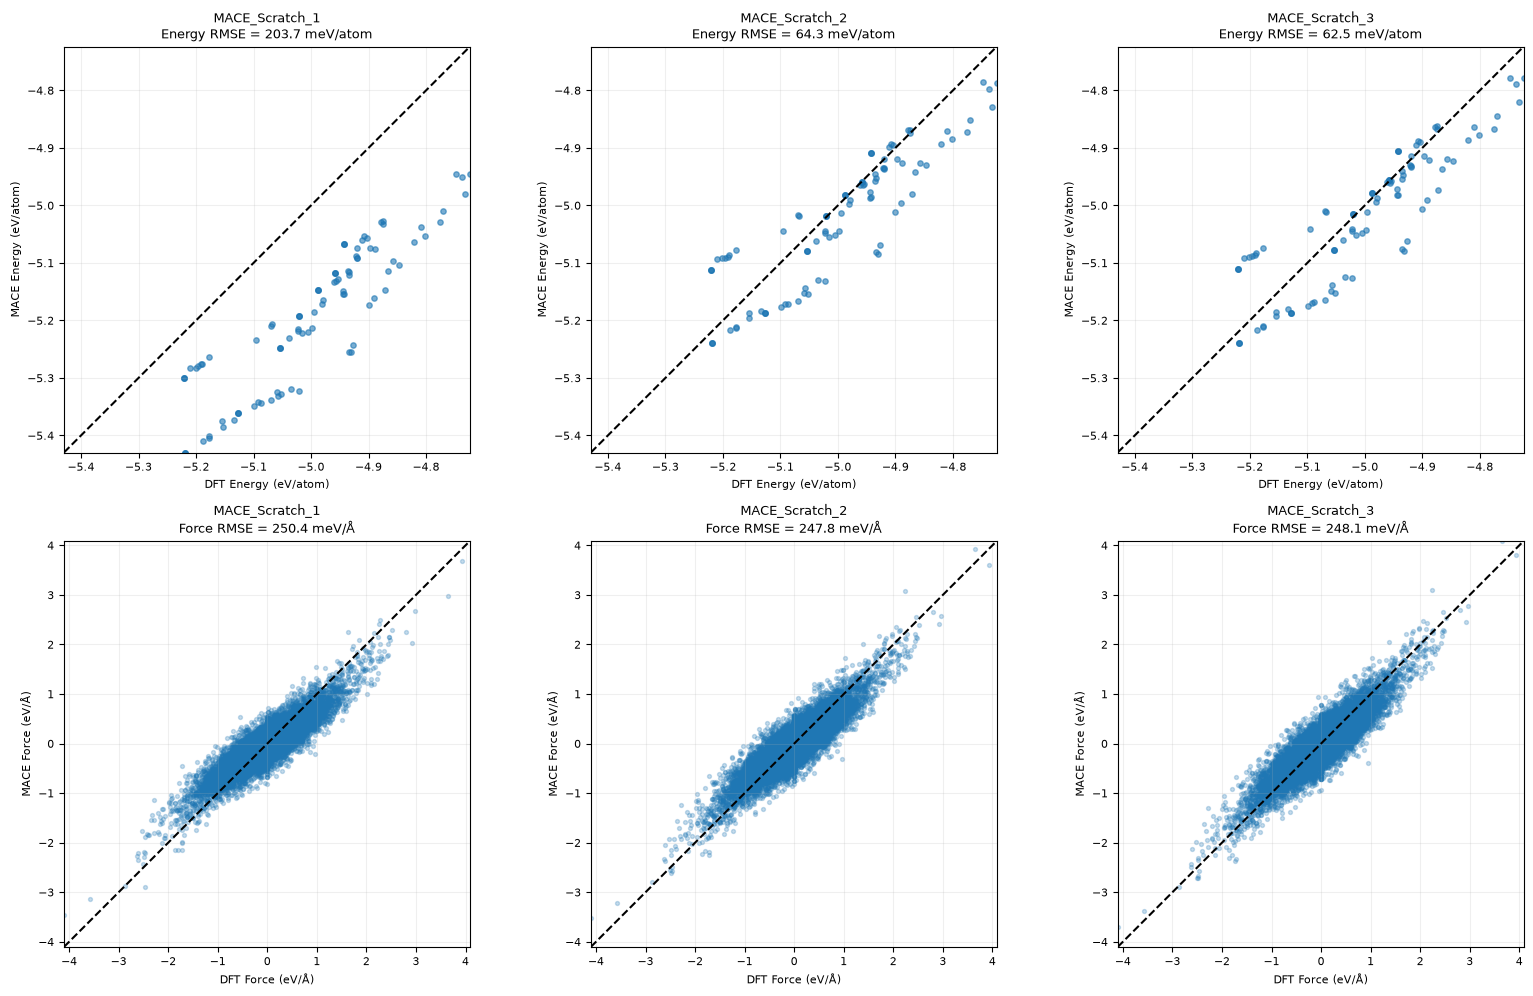


Evaluation completed. Results saved to: /home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs


In [12]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from ase.io import read
from mace.calculators import MACECalculator


# ============================================================
# 2. LOAD DFT TEST DATA
# ============================================================

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

test_atoms = read(str(TEST), index=":")

# DFT reference energy per atom
dft_energy = np.array([
    atoms.info["DFT_energy"] / len(atoms)
    for atoms in test_atoms
])

# DFT reference force components
dft_forces = np.concatenate([
    atoms.arrays["DFT_forces"].reshape(-1)
    for atoms in test_atoms
])

print("Test configurations:", len(test_atoms))
print("Computing device:", DEVICE)


# ============================================================
# 3. DEFINE MODEL EVALUATION FUNCTION
# ============================================================

def evaluate_scratch(model_name):

    model_dir = OUT / model_name / "models"

    models = sorted(model_dir.glob("*_compiled.model"))

    if not models:
        models = sorted(model_dir.glob("*.model"))

    if not models:
        raise FileNotFoundError(f"No model found in {model_dir}")

    # Load trained model
    calculator = MACECalculator(
        model_paths=str(models[-1]),
        device=DEVICE,
        default_dtype="float32"
    )

    predicted_energy = []
    predicted_forces = []

    # Predict energies and forces for all test configurations
    for atoms in test_atoms:

        structure = atoms.copy()
        structure.calc = calculator

        predicted_energy.append(
            structure.get_potential_energy() / len(structure)
        )

        predicted_forces.append(
            structure.get_forces().reshape(-1)
        )

    predicted_energy = np.array(predicted_energy)
    predicted_forces = np.concatenate(predicted_forces)

    # Calculate RMSE
    energy_rmse = 1000 * np.sqrt(
        np.mean((predicted_energy - dft_energy) ** 2)
    )

    force_rmse = 1000 * np.sqrt(
        np.mean((predicted_forces - dft_forces) ** 2)
    )

    return {
        "energy_pred": predicted_energy,
        "forces_pred": predicted_forces,
        "energy_rmse": energy_rmse,
        "force_rmse": force_rmse
    }


# ============================================================
# 4. EVALUATE ALL THREE TRAINED MODELS
# ============================================================

model_settings = {
    "MACE_Scratch_1": (0.01, 3),
    "MACE_Scratch_2": (0.001, 10),
    "MACE_Scratch_3": (0.0005, 20)
}

results = {}

for model_name in model_settings:
    print(f"Evaluating {model_name} ...")
    results[model_name] = evaluate_scratch(model_name)


# ============================================================
# 5. CREATE RMSE COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame([
    {
        "Model": name,
        "Learning rate": model_settings[name][0],
        "Epochs": model_settings[name][1],
        "Energy RMSE (meV/atom)": data["energy_rmse"],
        "Force RMSE (meV/Å)": data["force_rmse"]
    }
    for name, data in results.items()
])

display(comparison.round({
    "Energy RMSE (meV/atom)": 2,
    "Force RMSE (meV/Å)": 2
}))


# ============================================================
# 6. PLOT: 2 ROWS x 3 COLUMNS
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Use identical axis limits for fair comparison
energy_min = min(
    dft_energy.min(),
    *(r["energy_pred"].min() for r in results.values())
)
energy_max = max(
    dft_energy.max(),
    *(r["energy_pred"].max() for r in results.values())
)

force_min = min(
    dft_forces.min(),
    *(r["forces_pred"].min() for r in results.values())
)
force_max = max(
    dft_forces.max(),
    *(r["forces_pred"].max() for r in results.values())
)

for col, (name, data) in enumerate(results.items()):

    # ---------- ROW 1: ENERGY ----------
    ax = axes[0, col]

    ax.scatter(
        dft_energy,
        data["energy_pred"],
        s=15,
        alpha=0.6
    )

    ax.plot(
        [energy_min, energy_max],
        [energy_min, energy_max],
        "k--"
    )

    ax.set_xlim(energy_min, energy_max)
    ax.set_ylim(energy_min, energy_max)

    ax.set_xlabel("DFT Energy (eV/atom)")
    ax.set_ylabel("MACE Energy (eV/atom)")
    ax.set_title(
        f"{name}\nEnergy RMSE = {data['energy_rmse']:.1f} meV/atom"
    )

    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

    # ---------- ROW 2: FORCES ----------
    ax = axes[1, col]

    ax.scatter(
        dft_forces,
        data["forces_pred"],
        s=8,
        alpha=0.25
    )

    ax.plot(
        [force_min, force_max],
        [force_min, force_max],
        "k--"
    )

    ax.set_xlim(force_min, force_max)
    ax.set_ylim(force_min, force_max)

    ax.set_xlabel("DFT Force (eV/Å)")
    ax.set_ylabel("MACE Force (eV/Å)")
    ax.set_title(
        f"{name}\nForce RMSE = {data['force_rmse']:.1f} meV/Å"
    )

    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

plt.tight_layout()


# ============================================================
# 7. SAVE RESULTS
# ============================================================

comparison.to_csv(
    OUT / "MACE_Scratch_RMSE_Comparison.csv",
    index=False
)

fig.savefig(
    OUT / "MACE_Scratch_Parity_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nEvaluation completed. Results saved to:", OUT)

#### **What are we seeing here?**

We compared three MACE models trained from scratch using identical DFT datasets and model architectures but different learning rates and training epochs.

**Energy predictions:**

- The energy RMSE decreases substantially from **203.66 meV/atom (Scratch 1)** to **64.29 meV/atom (Scratch 2)**.
- Scratch 3 further reduces the energy RMSE to **62.48 meV/atom**, although the improvement over Scratch 2 is relatively small.
- The energy parity plots confirm that Scratch 2 and Scratch 3 show considerably better agreement with DFT.

**Force predictions:**

- The force RMSE remains nearly unchanged across the three models, ranging from **247.82 to 250.40 meV/Å**.
- The force parity plots show a similar distribution of predictions around the ideal diagonal, suggesting limited improvement in force accuracy.

**Conclusion:** ```Reducing the learning rate and increasing the number of training epochs substantially improves energy predictions in this experiment, but produces little improvement in force predictions. This demonstrates that improving one target property does not necessarily improve another```.

**Key takeaway:** Training settings significantly influence MACE performance. However, longer training alone does not guarantee better accuracy, and energy and force predictions should always be evaluated separately.

## **2. Model B : Pre-trained MACE Foundational Model** 

**What is a pretrained model?**

A pretrained model is a machine-learning model that has already learned from a large dataset. Instead of initializing a new model with random parameters, we load a model containing previously optimized parameters.

In this tutorial, we use **MACE-MP-0**, a foundation model trained on approximately 1.6 million atomic configurations from the Materials Project trajectory dataset (MPTrj), covering 89 chemical elements.

Unlike our scratch-trained models, MACE-MP-0 has already learned atomic interaction patterns from many different materials.

**How is this different from training from scratch?**

| Training from Scratch | Pretrained Model |
|---|---|
| Starts with randomly initialized parameters | Starts with previously learned parameters |
| Requires DFT training data | Can make predictions without additional training |
| Learns interactions from our Si–Li dataset | Uses knowledge acquired from a much larger materials dataset |
| Parameters change during training | Parameters remain unchanged during zero-shot evaluation |

**What is Zero-Shot Prediction?**

Zero-shot prediction means using a pretrained model to predict properties of our Si–Li configurations **without retraining or fine-tuning it on our Si–Li DFT dataset**.

The workflow is:

**Load pretrained MACE-MP-0 → Read Si–Li test configurations → Predict energies and forces → Compare with DFT**

### **Main Parameters Used**

| Parameter | Definition |
|---|---|
| `mace_mp()` | Loads a pretrained MACE foundation model as an ASE calculator. |
| `model="medium"` | Selects the medium-sized MACE-MP-0 model. |
| `device="cuda"` | Runs predictions on an NVIDIA GPU. |
| `default_dtype="float32"` | Uses 32-bit floating-point precision for calculations. |
| `dispersion=False` | Disables the optional D3 dispersion correction. |
| `get_potential_energy()` | Calculates the predicted potential energy of the atomic configuration. |
| `get_forces()` | Calculates the predicted forces acting on the atoms. |

**Important:** Unlike training from scratch, we do not need to specify learning rates, epochs, batch sizes, or a training loss function because we are not updating the pretrained model.

### **Objective**

Evaluate how accurately MACE-MP-0 predicts the energies and forces of our Si–Li configurations without additional training, and compare its performance against our scratch-trained models.

/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Computing device: cuda
Loading pretrained MACE-MP-0 medium model...
Using Materials Project MACE for MACECalculator with /home/bincy/.cache/mace/20231203mace128L1_epoch199model
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.
Pretrained model loaded successfully!
Test configurations: 96

----- PRETRAINED MACE-MP-0: TEST RESULTS -----
Energy RMSE: 168.41 meV/atom
Force RMSE:  270.50 meV/Å


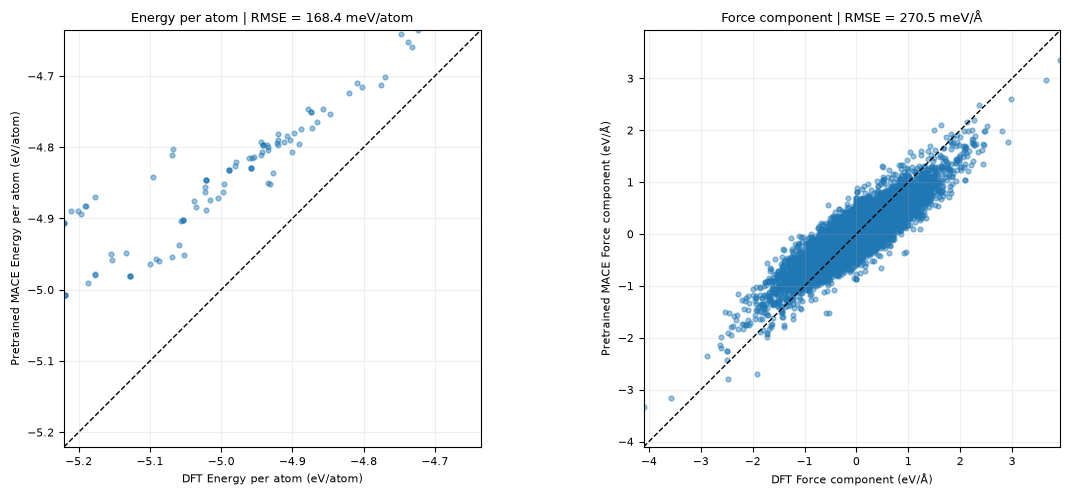


Pretrained evaluation completed!


In [13]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from ase.io import read
from mace.calculators import mace_mp


# ============================================================
# 2. LOAD PRETRAINED MACE-MP-0 MODEL
# ============================================================

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Computing device:", DEVICE)
print("Loading pretrained MACE-MP-0 medium model...")

calculator = mace_mp(
    model="medium",
    device=DEVICE,
    default_dtype="float32",
    dispersion=False
)

print("Pretrained model loaded successfully!")


# ============================================================
# 3. LOAD DFT TEST CONFIGURATIONS
# ============================================================

test_atoms = read(str(TEST), index=":")

dft_energy = np.array([
    atoms.info["DFT_energy"] / len(atoms)
    for atoms in test_atoms
])

dft_forces = np.concatenate([
    atoms.arrays["DFT_forces"].reshape(-1)
    for atoms in test_atoms
])

print("Test configurations:", len(test_atoms))


# ============================================================
# 4. PREDICT ENERGIES AND FORCES USING PRETRAINED MACE
# ============================================================

predicted_energy = []
predicted_forces = []

for atoms in test_atoms:

    structure = atoms.copy()
    structure.calc = calculator

    predicted_energy.append(
        structure.get_potential_energy() / len(structure)
    )

    predicted_forces.append(
        structure.get_forces().reshape(-1)
    )

predicted_energy = np.array(predicted_energy)
predicted_forces = np.concatenate(predicted_forces)


# ============================================================
# 5. CALCULATE RMSE
# ============================================================

energy_rmse = 1000 * np.sqrt(
    np.mean((predicted_energy - dft_energy) ** 2)
)

force_rmse = 1000 * np.sqrt(
    np.mean((predicted_forces - dft_forces) ** 2)
)

print("\n----- PRETRAINED MACE-MP-0: TEST RESULTS -----")
print(f"Energy RMSE: {energy_rmse:.2f} meV/atom")
print(f"Force RMSE:  {force_rmse:.2f} meV/Å")


# ============================================================
# 6. PLOT DFT vs PRETRAINED MACE PREDICTIONS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_data = [
    (
        axes[0], dft_energy, predicted_energy,
        "Energy per atom", "eV/atom",
        energy_rmse, "meV/atom"
    ),
    (
        axes[1], dft_forces, predicted_forces,
        "Force component", "eV/Å",
        force_rmse, "meV/Å"
    )
]

for ax, reference, predicted, label, unit, rmse, rmse_unit in plot_data:

    ax.scatter(reference, predicted, s=12, alpha=0.45)

    # Dashed line = perfect agreement with DFT
    low = min(reference.min(), predicted.min())
    high = max(reference.max(), predicted.max())

    ax.plot([low, high], [low, high], "k--", linewidth=1)

    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel(f"DFT {label} ({unit})")
    ax.set_ylabel(f"Pretrained MACE {label} ({unit})")
    ax.set_title(f"{label} | RMSE = {rmse:.1f} {rmse_unit}")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ============================================================
# 7. SAVE RESULTS FOR LATER COMPARISON
# ============================================================

pretrained_results = {
    "energy_pred": predicted_energy,
    "forces_pred": predicted_forces,
    "energy_rmse": energy_rmse,
    "force_rmse": force_rmse
}

pretrained_summary = pd.DataFrame([{
    "Model": "MACE-MP-0 medium (zero-shot)",
    "Energy RMSE (meV/atom)": energy_rmse,
    "Force RMSE (meV/Å)": force_rmse
}])

pretrained_summary.to_csv(
    OUT / "MACE_Pretrained_Results.csv",
    index=False
)

fig.savefig(
    OUT / "MACE_Pretrained_Parity.png",
    dpi=300,
    bbox_inches="tight"
)

print("\nPretrained evaluation completed!")

### **What are we seeing here?**

We evaluated the pretrained **MACE-MP-0 medium** foundation model on 96 Si–Li DFT test configurations without any additional training (zero-shot evaluation).

The model achieved:

- **Energy RMSE:** 168.41 meV/atom
- **Force RMSE:** 270.50 meV/Å

**Energy predictions:**

- Most points lie above the diagonal line, indicating that the pretrained model systematically predicts higher energies than our DFT reference calculations.
- The predicted energies nevertheless follow the overall trend of the DFT energies.
- Differences in DFT computational settings or atomic-energy references may contribute to the observed energy offset.

**Force predictions:**

- Predicted atomic forces show a clear correlation with DFT forces.
- However, noticeable deviations remain, with a force RMSE of 270.50 meV/Å.

**Conclusion:** The pretrained MACE-MP-0 model captures some energy and force trends for Si–Li configurations without material-specific training, but its predictions show substantial errors relative to our DFT reference data.

Compared with our scratch-trained models, its test RMSE values are higher, although differences in energy-reference conventions must be considered when interpreting the energy results.

### **Comparison between Scratch model and pre-trained model**

,Model,Energy RMSE (meV/atom),Force RMSE (meV/Å)
0,MACE Scratch 3,62.48,248.13
1,Pretrained MACE-MP-0,168.41,270.50


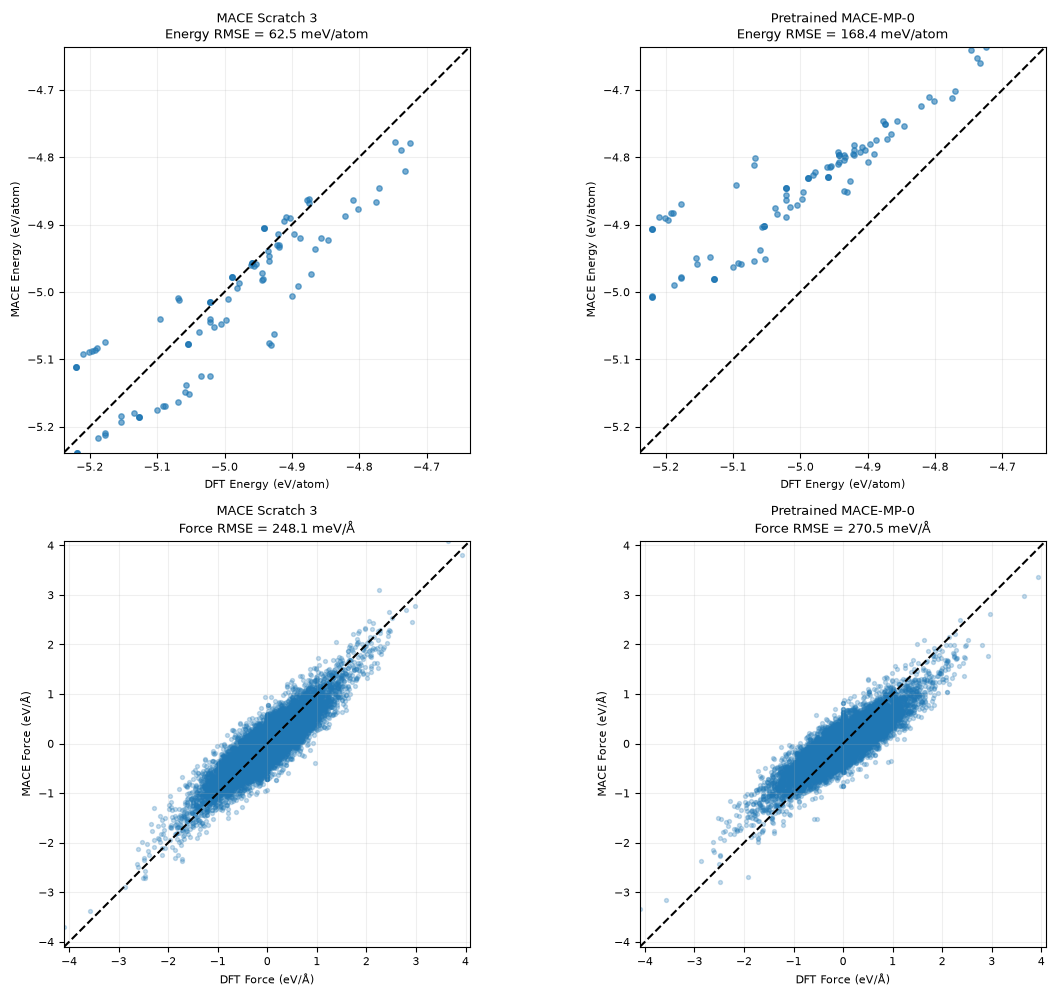

In [14]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 2. COLLECT MODEL RESULTS
# ============================================================

scratch = results["MACE_Scratch_3"]
pretrained = pretrained_results

models = {
    "MACE Scratch 3": scratch,
    "Pretrained MACE-MP-0": pretrained
}


# ============================================================
# 3. CREATE RMSE COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame([
    {
        "Model": name,
        "Energy RMSE (meV/atom)": data["energy_rmse"],
        "Force RMSE (meV/Å)": data["force_rmse"]
    }
    for name, data in models.items()
])

display(comparison.round(2))


# ============================================================
# 4. SET COMMON AXIS LIMITS
# ============================================================

energy_min = min(
    dft_energy.min(),
    *(m["energy_pred"].min() for m in models.values())
)
energy_max = max(
    dft_energy.max(),
    *(m["energy_pred"].max() for m in models.values())
)

force_min = min(
    dft_forces.min(),
    *(m["forces_pred"].min() for m in models.values())
)
force_max = max(
    dft_forces.max(),
    *(m["forces_pred"].max() for m in models.values())
)


# ============================================================
# 5. PLOT 2 ROWS x 2 COLUMNS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for col, (name, data) in enumerate(models.items()):

    # Row 1: Energy parity
    ax = axes[0, col]

    ax.scatter(
        dft_energy,
        data["energy_pred"],
        s=15,
        alpha=0.6
    )

    ax.plot(
        [energy_min, energy_max],
        [energy_min, energy_max],
        "k--"
    )

    ax.set_xlim(energy_min, energy_max)
    ax.set_ylim(energy_min, energy_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("DFT Energy (eV/atom)")
    ax.set_ylabel("MACE Energy (eV/atom)")
    ax.set_title(
        f"{name}\n"
        f"Energy RMSE = {data['energy_rmse']:.1f} meV/atom"
    )
    ax.grid(alpha=0.2)

    # Row 2: Force parity
    ax = axes[1, col]

    ax.scatter(
        dft_forces,
        data["forces_pred"],
        s=8,
        alpha=0.25
    )

    ax.plot(
        [force_min, force_max],
        [force_min, force_max],
        "k--"
    )

    ax.set_xlim(force_min, force_max)
    ax.set_ylim(force_min, force_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("DFT Force (eV/Å)")
    ax.set_ylabel("MACE Force (eV/Å)")
    ax.set_title(
        f"{name}\n"
        f"Force RMSE = {data['force_rmse']:.1f} meV/Å"
    )
    ax.grid(alpha=0.2)

plt.tight_layout()


# ============================================================
# 6. SAVE RESULTS
# ============================================================

comparison.to_csv(
    OUT / "Scratch_vs_Pretrained_RMSE.csv",
    index=False
)

fig.savefig(
    OUT / "Scratch_vs_Pretrained_Parity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### **What are we seeing here?**

**Energy predictions:**

- MACE_Scratch_3 achieves a lower energy RMSE (**62.48 meV/atom**) than the pretrained model (**168.41 meV/atom**).
- The pretrained model exhibits a systematic positive energy offset relative to our DFT calculations.
- Differences in energy-reference conventions may contribute to this offset, so the raw energy RMSE comparison should be interpreted carefully.

**Force predictions:**

- MACE_Scratch_3 achieves a force RMSE of **248.13 meV/Å**, compared with **270.50 meV/Å** for pretrained MACE-MP-0.
- Both models reproduce the overall trends in DFT atomic forces, although noticeable prediction errors remain.

**Conclusion:** For our Si–Li test dataset, the material-specific scratch-trained model achieves lower raw energy and force RMSE than the zero-shot pretrained model. However, this does not mean that training from scratch is always preferable; the pretrained model has not yet been adapted to our Si–Li reference data.



--------------------------------------------------------
# **Next step: Fine-tune MACE-MP-0 using our Si–Li DFT training configurations and investigate whether combining pretrained knowledge with material-specific training improves the predictions.**
-----------------------------------------------------------------------------------------------

## **3. Model C : Fine Tuning Pre-trained MACE MP-0 Model** 

**What is fine-tuning?**

Fine-tuning means taking an already-trained machine-learning model and training it further using our own DFT dataset.

Instead of initializing random parameters as we did for MACE_Scratch_1, 2, and 3, we start with the parameters learned by the pretrained **MACE-MP-0 medium** foundation model.

During fine-tuning, these parameters are updated so that the model better reproduces the energies and forces of our Si–Li configurations.

**Fine-tuning workflow:**

**Pretrained MACE-MP-0 → Load Si–Li DFT training data → Predict energies and forces → Calculate errors → Update model parameters → Fine-tuned Si–Li potential**

### **Main Parameters Used in Fine-Tuning**

| Parameter | Definition |
|---|---|
| `--foundation_model="medium"` | Loads pretrained MACE-MP-0 medium as the starting model. |
| `--multiheads_finetuning=False` | Uses standard single-head fine-tuning rather than multihead fine-tuning. |
| `--train_file` | Si–Li DFT configurations used to update the model parameters. |
| `--valid_file` | Separate DFT configurations used to monitor performance during training. |
| `--E0s="estimated"` | Adjusts the element-specific reference energies to better match our DFT dataset. |
| `--lr` | Learning rate controlling how much the pretrained parameters change during optimization. |
| `--max_num_epochs` | Maximum number of passes through the training dataset. |
| `--batch_size` | Number of configurations processed per training batch. |
| `--energy_weight` | Relative importance assigned to energy errors during training. |
| `--forces_weight` | Relative importance assigned to force errors during training. |
| `--device` | Computing device used for training (GPU or CPU). |

**Important difference:** In scratch training, the model parameters are initialized randomly. In fine-tuning, they are initialized using the pretrained MACE-MP-0 model. Both methods update parameters using our DFT training data.

**Objective:** Determine whether adapting MACE-MP-0 to our Si–Li dataset improves its predictions compared with zero-shot use and training from scratch.

#### ```MACE_FineTune_1```

### **Model Train**

In [15]:
# ============================================================
# 1. FINE-TUNING SETTINGS
# ============================================================

FT_MODEL_NAME = "MACE_Finetuned_1"

FT_LEARNING_RATE = 0.0001
FT_EPOCHS = 10
FT_BATCH_SIZE = 2

RUN_FINETUNING = True


# ============================================================
# 2. CREATE OUTPUT DIRECTORIES
# ============================================================

ft_prefix = OUT / FT_MODEL_NAME

for part in ["models", "checkpoints", "results", "logs"]:
    (ft_prefix / part).mkdir(parents=True, exist_ok=True)


# ============================================================
# 3. DEFINE MACE FINE-TUNING COMMAND
# ============================================================

ft_args = [
    "mace_run_train",

    f"--name={FT_MODEL_NAME}",

    # Load pretrained MACE-MP-0 medium
    "--foundation_model=medium",
    "--multiheads_finetuning=False",

    # Si-Li DFT dataset
    f"--train_file={TRAIN}",
    f"--valid_file={VALID}",
    "--energy_key=DFT_energy",
    "--forces_key=DFT_forces",

    # Fine-tuning settings
    "--E0s=estimated",
    f"--lr={FT_LEARNING_RATE}",
    f"--max_num_epochs={FT_EPOCHS}",
    f"--batch_size={FT_BATCH_SIZE}",
    "--valid_batch_size=2",

    # Energy and force loss
    "--energy_weight=1.0",
    "--forces_weight=100.0",

    # Optimizer and numerical settings
    "--weight_decay=0.0",
    "--default_dtype=float32",
    f"--device={DEVICE}",
    "--num_workers=0",
    "--seed=42",

    # Output directories
    f"--model_dir={ft_prefix / 'models'}",
    f"--checkpoints_dir={ft_prefix / 'checkpoints'}",
    f"--results_dir={ft_prefix / 'results'}",
    f"--log_dir={ft_prefix / 'logs'}",
]


# ============================================================
# 4. RUN FINE-TUNING
# ============================================================

if RUN_FINETUNING:

    print("=" * 55)
    print("Model:", FT_MODEL_NAME)
    print("Foundation model: MACE-MP-0 medium")
    print("Learning rate:", FT_LEARNING_RATE)
    print("Epochs:", FT_EPOCHS)
    print("Batch size:", FT_BATCH_SIZE)
    print("=" * 55)

    run_mace(
        ft_args,
        ft_prefix / "logs" / "terminal.log"
    )

else:
    print("Fine-tuning skipped.")

Model: MACE_Finetuned_1
Foundation model: MACE-MP-0 medium
Learning rate: 0.0001
Epochs: 10
Batch size: 2
Command: mace_run_train --name=MACE_Finetuned_1 --foundation_model=medium --multiheads_finetuning=False --train_file=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/data/SiLi_train.xyz --valid_file=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/data/SiLi_valid.xyz --energy_key=DFT_energy --forces_key=DFT_forces --E0s=estimated --lr=0.0001 --max_num_epochs=10 --batch_size=2 --valid_batch_size=2 --energy_weight=1.0 --forces_weight=100.0 --weight_decay=0.0 --default_dtype=float32 --device=cuda --num_workers=0 --seed=42 --model_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Finetuned_1/models --checkpoints_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Finetuned_1/checkpoints --results_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs/MACE_Finetuned_1/results --log_dir=/home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_

#### **Evaluate the fine-tuned model**

/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/home/bincy/miniconda3/envs/mace_env/lib/python3.11/site-packages/mace/calculators/mace.py:226: UserWarning: 'torch.load' received a zip file that looks like a TorchScript archive dispatching to 'torch.jit.load' (call 'torch.jit.load' directly to silence this warning)
  torch.load(f=model_path, map_location=device)



----- FINE-TUNED MACE: TEST RESULTS -----
Energy RMSE: 46.28 meV/atom
Force RMSE:  227.45 meV/Å


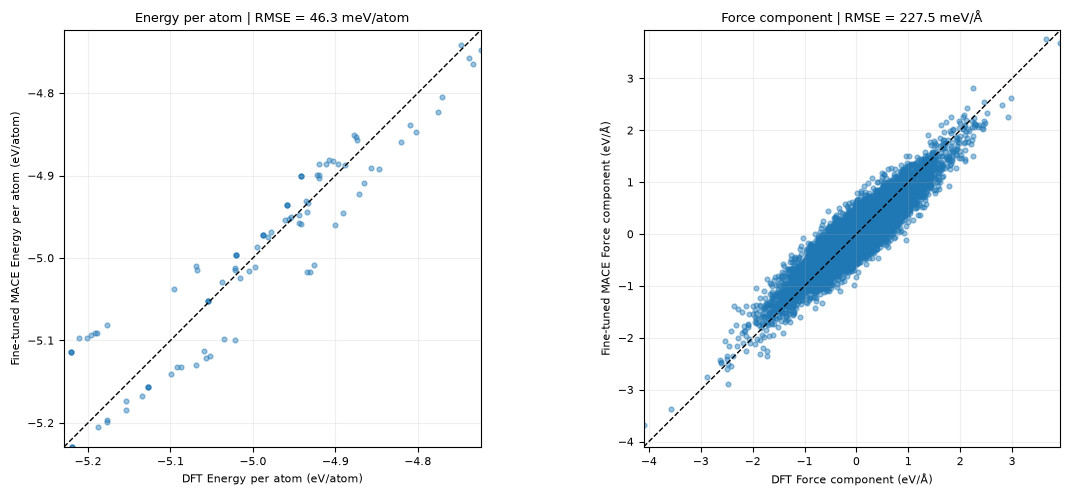

In [16]:
# ============================================================
# 1. EVALUATE FINE-TUNED MACE MODEL
# ============================================================

finetuned = evaluate_scratch("MACE_Finetuned_1")

print("\n----- FINE-TUNED MACE: TEST RESULTS -----")
print(f"Energy RMSE: {finetuned['energy_rmse']:.2f} meV/atom")
print(f"Force RMSE:  {finetuned['force_rmse']:.2f} meV/Å")


# ============================================================
# 2. PLOT DFT vs FINE-TUNED MACE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_data = [
    (
        dft_energy, finetuned["energy_pred"],
        "Energy per atom", "eV/atom",
        finetuned["energy_rmse"], "meV/atom"
    ),
    (
        dft_forces, finetuned["forces_pred"],
        "Force component", "eV/Å",
        finetuned["force_rmse"], "meV/Å"
    )
]

for ax, (ref, pred, label, unit, rmse, rmse_unit) in zip(axes, plot_data):

    ax.scatter(ref, pred, s=12, alpha=0.45)

    low = min(ref.min(), pred.min())
    high = max(ref.max(), pred.max())

    ax.plot([low, high], [low, high], "k--", linewidth=1)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel(f"DFT {label} ({unit})")
    ax.set_ylabel(f"Fine-tuned MACE {label} ({unit})")
    ax.set_title(f"{label} | RMSE = {rmse:.1f} {rmse_unit}")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### **What are we seeing here?**

We fine-tuned the pretrained MACE-MP-0 medium model using 192 Si–Li DFT training configurations for 10 epochs and evaluated it against the same 96 independent DFT test configurations.

The fine-tuned model achieved:

- **Energy RMSE:** 46.28 meV/atom
- **Force RMSE:** 227.45 meV/Å

**Energy predictions:** The fine-tuned model shows considerably better agreement with DFT than the zero-shot pretrained model. The systematic energy offset is substantially reduced.

**Force predictions:** The atomic-force predictions remain concentrated around the ideal diagonal, with lower errors than the zero-shot and scratch-trained models.

**Conclusion:** Fine-tuning the pretrained MACE-MP-0 model using our material-specific Si–Li DFT data improves both energy and force prediction accuracy. In this tutorial experiment, the fine-tuned model outperforms the scratch-trained and zero-shot pretrained models on the selected test configurations.

These improvements demonstrate the potential advantage of combining pretrained knowledge with material-specific DFT data, although additional validation is required before using the model for quantitative diffusion simulations.

## **Final Comparison: Scratch vs Pretrained vs Fine-Tuned MACE**

We have now explored three approaches to machine-learning interatomic potentials:

- **Training from scratch:** Building and training a new MACE model using our Si–Li DFT dataset.
- **Pretrained model (zero-shot):** Using an existing MACE-MP-0 foundation model without additional training.
- **Fine-tuning:** Starting from pretrained MACE-MP-0 and updating its parameters using our Si–Li DFT dataset.

We will compare all three models using the same 96 DFT test configurations.

The comparison includes energy and force parity plots and a summary table of RMSE values. Lower RMSE values indicate better agreement with DFT.

**Note:** Raw energy RMSE can be affected by differences in energy-reference conventions, particularly for the zero-shot pretrained model.

FINAL MODEL COMPARISON


,Model,Energy RMSE (meV/atom),Force RMSE (meV/Å)
0,Scratch MACE,62.48,248.13
1,Pretrained MACE-MP-0,168.41,270.50
2,Fine-tuned MACE,46.28,227.45


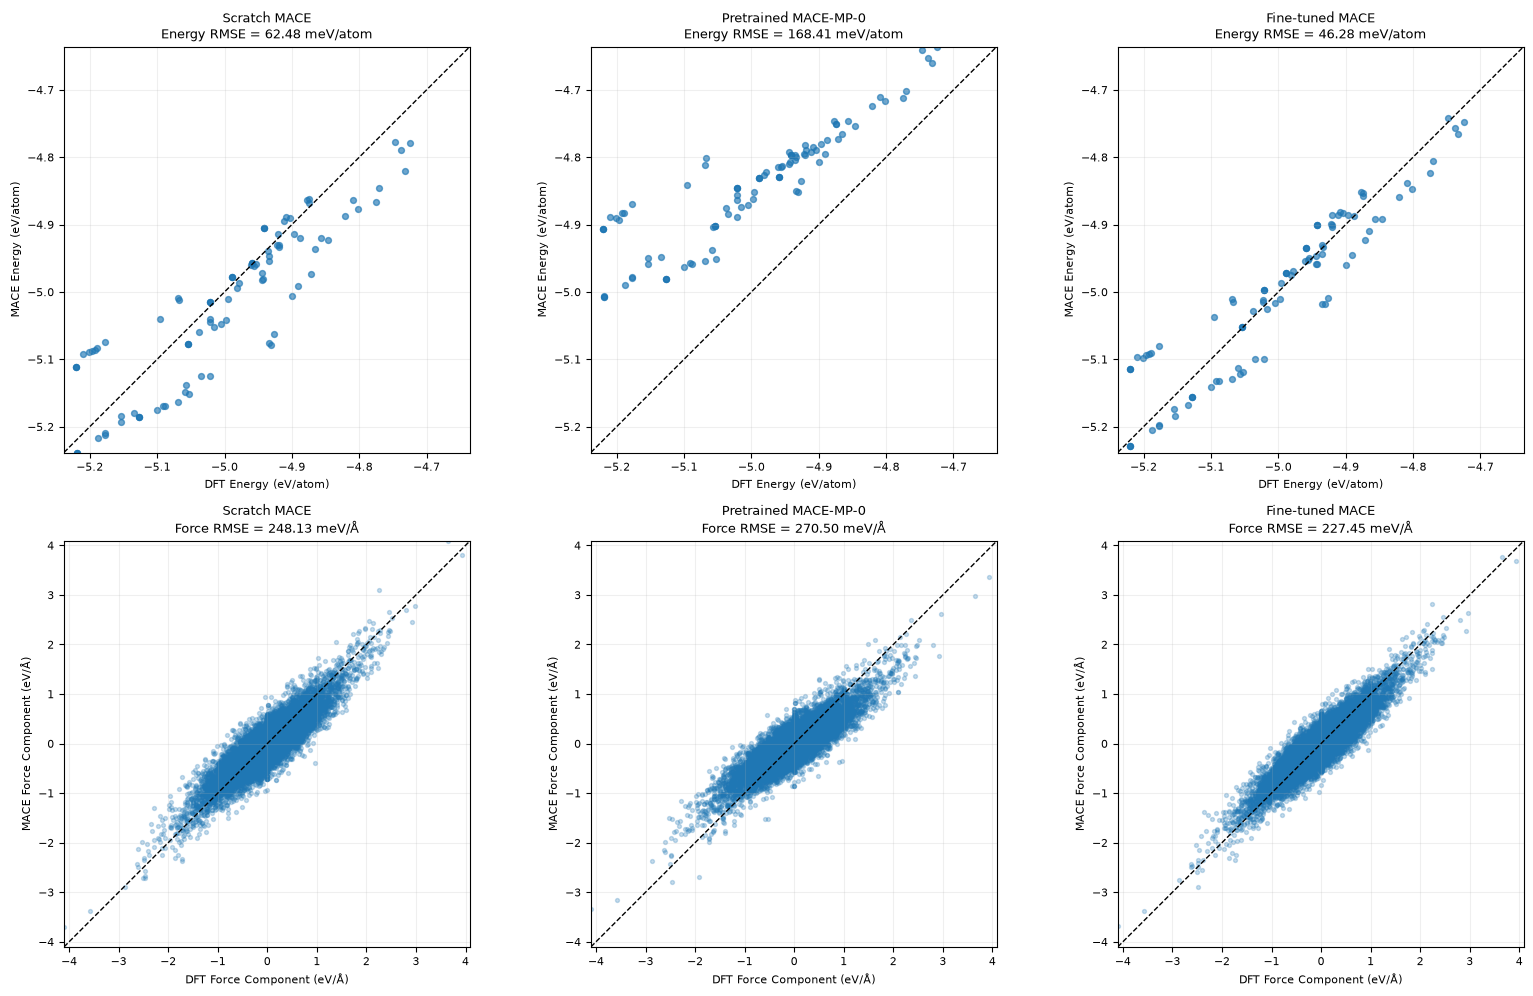


Comparison completed!
Results saved in: /home/bincy/Desktop/MLIP_tutorial/github_tutorial/mace_runs


In [17]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 2. COLLECT THE THREE MODEL RESULTS
# ============================================================

models = {
    "Scratch MACE": results["MACE_Scratch_3"],
    "Pretrained MACE-MP-0": pretrained_results,
    "Fine-tuned MACE": finetuned
}

# All predictions use the same DFT test configurations
# dft_energy: DFT energies in eV/atom
# dft_forces: DFT force components in eV/Å


# ============================================================
# 3. CREATE RMSE COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame([
    {
        "Model": name,
        "Energy RMSE (meV/atom)": data["energy_rmse"],
        "Force RMSE (meV/Å)": data["force_rmse"]
    }
    for name, data in models.items()
])

print("FINAL MODEL COMPARISON")
display(comparison.round(2))


# ============================================================
# 4. DEFINE COMMON AXIS LIMITS
# ============================================================

# Same energy scales across all three energy plots
energy_min = min(
    dft_energy.min(),
    *(data["energy_pred"].min() for data in models.values())
)

energy_max = max(
    dft_energy.max(),
    *(data["energy_pred"].max() for data in models.values())
)

# Same force scales across all three force plots
force_min = min(
    dft_forces.min(),
    *(data["forces_pred"].min() for data in models.values())
)

force_max = max(
    dft_forces.max(),
    *(data["forces_pred"].max() for data in models.values())
)


# ============================================================
# 5. CREATE 2 ROW x 3 COLUMN PARITY FIGURE
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for col, (name, data) in enumerate(models.items()):

    # --------------------------------------------------------
    # ROW 1: ENERGY PARITY
    # --------------------------------------------------------

    ax = axes[0, col]

    ax.scatter(
        dft_energy,
        data["energy_pred"],
        s=18,
        alpha=0.65
    )

    # Dashed line = perfect agreement with DFT
    ax.plot(
        [energy_min, energy_max],
        [energy_min, energy_max],
        "k--",
        linewidth=1
    )

    ax.set_xlim(energy_min, energy_max)
    ax.set_ylim(energy_min, energy_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("DFT Energy (eV/atom)")
    ax.set_ylabel("MACE Energy (eV/atom)")

    ax.set_title(
        f"{name}\n"
        f"Energy RMSE = {data['energy_rmse']:.2f} meV/atom"
    )

    ax.grid(alpha=0.2)

    # --------------------------------------------------------
    # ROW 2: FORCE PARITY
    # --------------------------------------------------------

    ax = axes[1, col]

    ax.scatter(
        dft_forces,
        data["forces_pred"],
        s=8,
        alpha=0.25
    )

    ax.plot(
        [force_min, force_max],
        [force_min, force_max],
        "k--",
        linewidth=1
    )

    ax.set_xlim(force_min, force_max)
    ax.set_ylim(force_min, force_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("DFT Force Component (eV/Å)")
    ax.set_ylabel("MACE Force Component (eV/Å)")

    ax.set_title(
        f"{name}\n"
        f"Force RMSE = {data['force_rmse']:.2f} meV/Å"
    )

    ax.grid(alpha=0.2)

plt.tight_layout()


# ============================================================
# 6. SAVE THE FIGURE AND TABLE
# ============================================================

fig.savefig(
    OUT / "MACE_Final_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

comparison.to_csv(
    OUT / "MACE_Final_Comparison.csv",
    index=False
)

plt.show()

print("\nComparison completed!")
print("Results saved in:", OUT)

### **What are we seeing here?**

The three approaches show different levels of agreement with our Si–Li DFT reference calculations.

**Energy predictions:**

- The scratch-trained model achieves an energy RMSE of **62.48 meV/atom**.
- The zero-shot pretrained model has a larger raw energy RMSE of **168.41 meV/atom**, partly potentially reflecting differences in DFT energy references.
- Fine-tuning reduces the energy RMSE to **46.28 meV/atom**, the lowest among the three models.

**Force predictions:**

- Scratch-trained MACE achieves a force RMSE of **248.13 meV/Å**.
- Pretrained MACE-MP-0 gives **270.50 meV/Å** without additional training.
- Fine-tuned MACE reduces the force RMSE to **227.45 meV/Å**.

**Conclusion:** For our Si–Li tutorial dataset, fine-tuning the pretrained MACE-MP-0 model produces the lowest energy and force prediction errors among the three approaches. This illustrates how pretrained knowledge can be adapted to material-specific DFT calculations.

However, these results are based on a small tutorial dataset. Further validation is needed before using the models for quantitative diffusion simulations.